In [1]:
!pip install tensorflow tensorflow-hub opencv-python

In [2]:
import tensorflow as tf
import tensorflow_hub as hub
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [3]:
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d0/1"

detector = hub.load(MODEL_URL)

print("Model loaded successfully!")

Model loaded successfully!


In [4]:
COCO_CLASSES = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus",
    "train", "truck", "boat", "traffic light", "fire hydrant",
    "stop sign", "parking meter", "bench", "bird", "cat", "dog",
    "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe",
    "backpack", "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite", "baseball bat",
    "baseball glove", "skateboard", "surfboard", "tennis racket",
    "bottle", "wine glass", "cup", "fork", "knife", "spoon", "bowl",
    "banana", "apple", "sandwich", "orange", "broccoli", "carrot",
    "hot dog", "pizza", "donut", "cake", "chair", "couch",
    "potted plant", "bed", "dining table", "toilet", "tv", "laptop",
    "mouse", "remote", "keyboard", "cell phone", "microwave",
    "oven", "toaster", "sink", "refrigerator", "book", "clock",
    "vase", "scissors", "teddy bear", "hair drier", "toothbrush"
]

In [5]:
def detect_objects_with_boxes(image_path, detector):
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError("Could not read the image.")

    result_image = image.copy()

    input_tensor = tf.convert_to_tensor(image)
    input_tensor = input_tensor[tf.newaxis, ...]

    detections = detector(input_tensor)

    num_detections = int(detections["num_detections"].numpy())

    detection_boxes = detections["detection_boxes"].numpy()[0]
    detection_classes = detections["detection_classes"].numpy()[0].astype(np.int32)
    detection_scores = detections["detection_scores"].numpy()[0]

    height, width, _ = image.shape
    confidence_threshold = 0.5

    for i in range(num_detections):
        score = detection_scores[i]

        if score > confidence_threshold:
            y_min, x_min, y_max, x_max = detection_boxes[i]

            x_min = int(x_min * width)
            x_max = int(x_max * width)
            y_min = int(y_min * height)
            y_max = int(y_max * height)

            class_id = detection_classes[i]

            if 1 <= class_id <= len(COCO_CLASSES):
                class_name = COCO_CLASSES[class_id - 1]
            else:
                class_name = "Unknown"

            label = f"{class_name}: {score:.2f}"

            cv2.rectangle(
                result_image,
                (x_min, y_min),
                (x_max, y_max),
                (0, 255, 0),
                2
            )

            cv2.putText(
                result_image,
                label,
                (x_min, max(y_min - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2
            )

    return result_image

In [13]:
uploaded = files.upload()

image_path = next(iter(uploaded))

Saving TNIE_import_uploads_user_ckeditor_images_article_2018_3_12_LESS.avif to TNIE_import_uploads_user_ckeditor_images_article_2018_3_12_LESS.avif


/tmp/ipykernel_920/494461897.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  num_detections = int(detections["num_detections"].numpy())


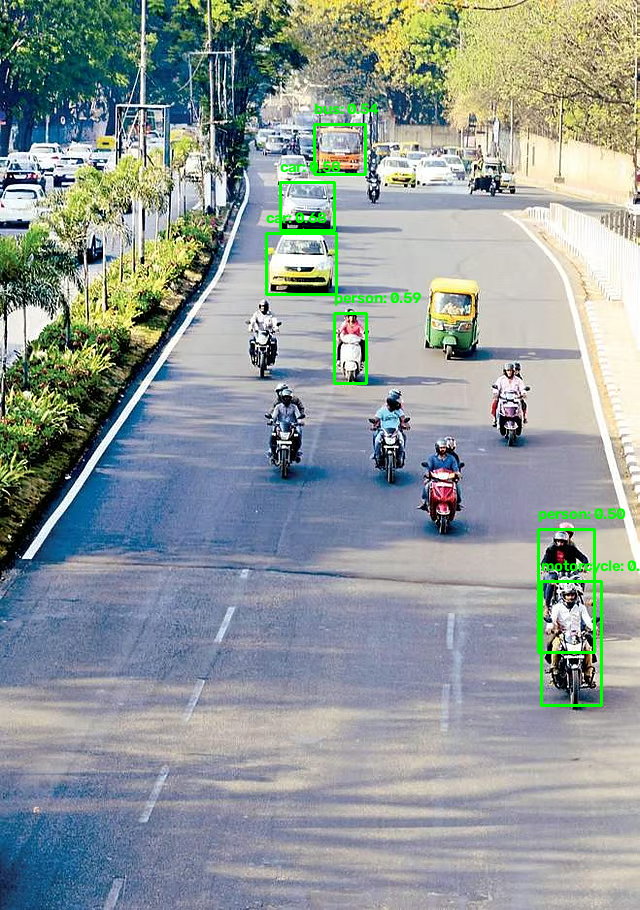

In [14]:
result_image = detect_objects_with_boxes(image_path, detector)

cv2_imshow(result_image)